Original Image Shape: (8, 8)

Singular Values:
 [48.307845   24.95585264  8.02075326  6.02937301  3.53447932  0.61576328
  0.          0.        ]

Singular Values: 2
Reconstruction Error: 10.66
Compression Ratio: 1.88

Singular Values: 5
Reconstruction Error: 0.62
Compression Ratio: 0.75

Singular Values: 8
Reconstruction Error: 0.0
Compression Ratio: 0.47

Singular Values: 15
Reconstruction Error: 0.0
Compression Ratio: 0.25


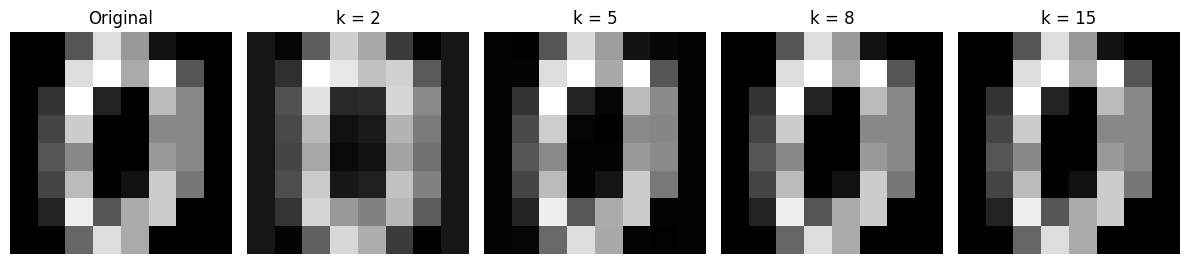

In [9]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits

# 1. Load Grayscale Image
image = load_digits().images[0]

print("Original Image Shape:", image.shape)

# 2. Singular Value Decomposition
U, S, VT = np.linalg.svd(image, full_matrices=False)

print("\nSingular Values:\n", S)

# 3. Image Reconstruction
k_values = [2, 5, 8, 15]
fig, axes = plt.subplots(1, 5, figsize=(12, 4))

axes[0].imshow(image, cmap='gray')
axes[0].set_title("Original")

original_size = image.size

# 4. Reconstruction, Error and Compression
for ax, k in zip(axes[1:], k_values):
    reconstructed = U[:, :k] @ np.diag(S[:k]) @ VT[:k, :]

    error = np.linalg.norm(image - reconstructed, 'fro')
    ratio = original_size / (k * (image.shape[0] +
                                  image.shape[1] + 1))

    ax.imshow(reconstructed, cmap='gray')
    ax.set_title(f"k = {k}")

    print("\nSingular Values:", k)
    print("Reconstruction Error:", round(error, 2))
    print("Compression Ratio:", round(ratio, 2))

    ax.axis('off')

axes[0].axis('off')
plt.tight_layout()
plt.show()
